In [1]:
import os, sys
os.environ['OPENBLAS_NUM_THREADS'] = '8'
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import anndata as ad
import matplotlib.pyplot as plt

In [2]:
geo = 'GSE159478'
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', geo)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', geo)

In [3]:
adata_dict = dict()
for i in range(1, 5):
    pfx = f'GSM483054{i}_T{i}_'
    adata_i = sc.read_10x_mtx(pth_in, prefix = pfx)
    adata_dict[pfx] = adata_i.copy()
    print(pfx, adata_i, '\n')
adata = ad.concat(adata_dict, label = 'sample')
adata.obs_names_make_unique(); adata

GSM4830541_T1_ AnnData object with n_obs × n_vars = 8724 × 55472
    var: 'gene_ids' 

GSM4830542_T2_ AnnData object with n_obs × n_vars = 9580 × 55472
    var: 'gene_ids' 

GSM4830543_T3_ AnnData object with n_obs × n_vars = 8434 × 55472
    var: 'gene_ids' 

GSM4830544_T4_ AnnData object with n_obs × n_vars = 9424 × 55472
    var: 'gene_ids' 



/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 36162 × 55472
    obs: 'sample'

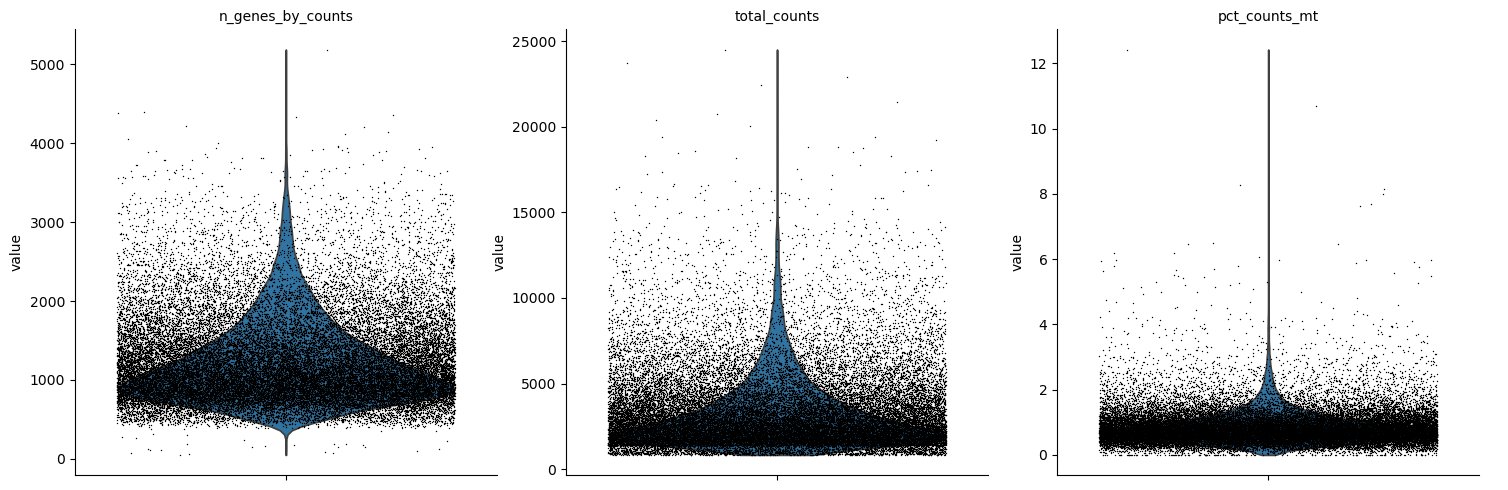

In [4]:
adata.var['mt'] = adata.var_names.str.startswith('mt-')
sc.pp.calculate_qc_metrics(adata, qc_vars = ['mt'], percent_top = None, inplace = True, log1p = False)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter = .4, multi_panel = True)

In [5]:
adata = adata[
    (adata.obs.n_genes_by_counts >= 400) &
    (adata.obs.n_genes_by_counts <= 4000) &
    (adata.obs.pct_counts_mt <= 5)].copy()
adata

AnnData object with n_obs × n_vars = 36064 × 55472
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1483 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.



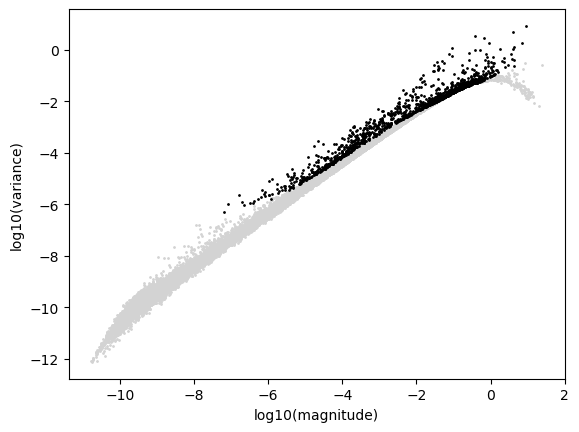

In [6]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)

In [7]:
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'sample')

2026-06-30 19:54:07,558 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-06-30 19:54:12,368 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-06-30 19:54:12,552 - harmonypy - INFO - Iteration 1 of 10
2026-06-30 19:54:21,061 - harmonypy - INFO - Iteration 2 of 10
2026-06-30 19:54:29,487 - harmonypy - INFO - Iteration 3 of 10
2026-06-30 19:54:37,895 - harmonypy - INFO - Converged after 3 iterations


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


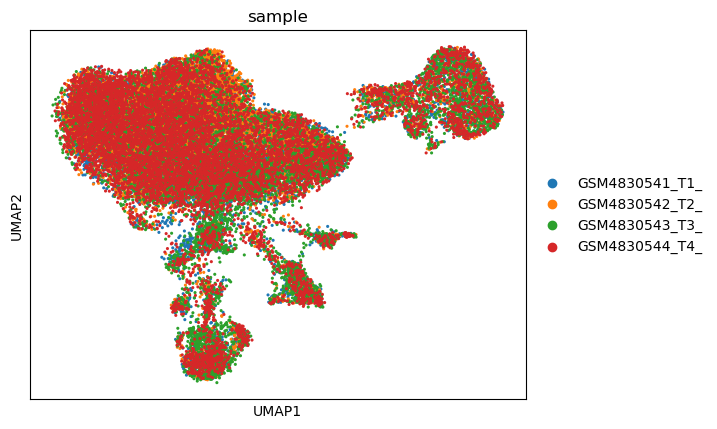

In [8]:
sc.pp.neighbors(adata, n_pcs = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(adata)
sc.pl.umap(adata, color = 'sample', size = 20)

/tmp/ipykernel_350967/4106595113.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


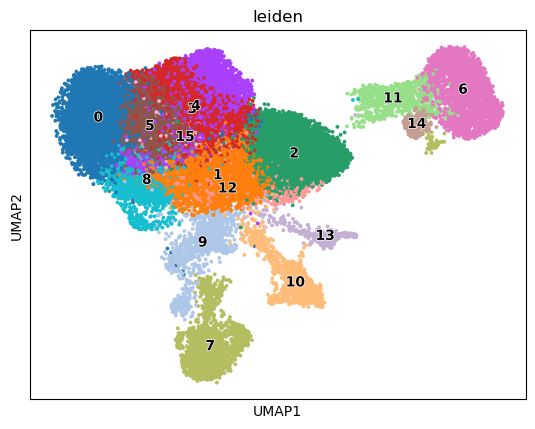

In [9]:
sc.tl.leiden(adata)
sc.pl.umap(adata, color = 'leiden', size = 30, legend_loc = 'on data', legend_fontoutline = True)

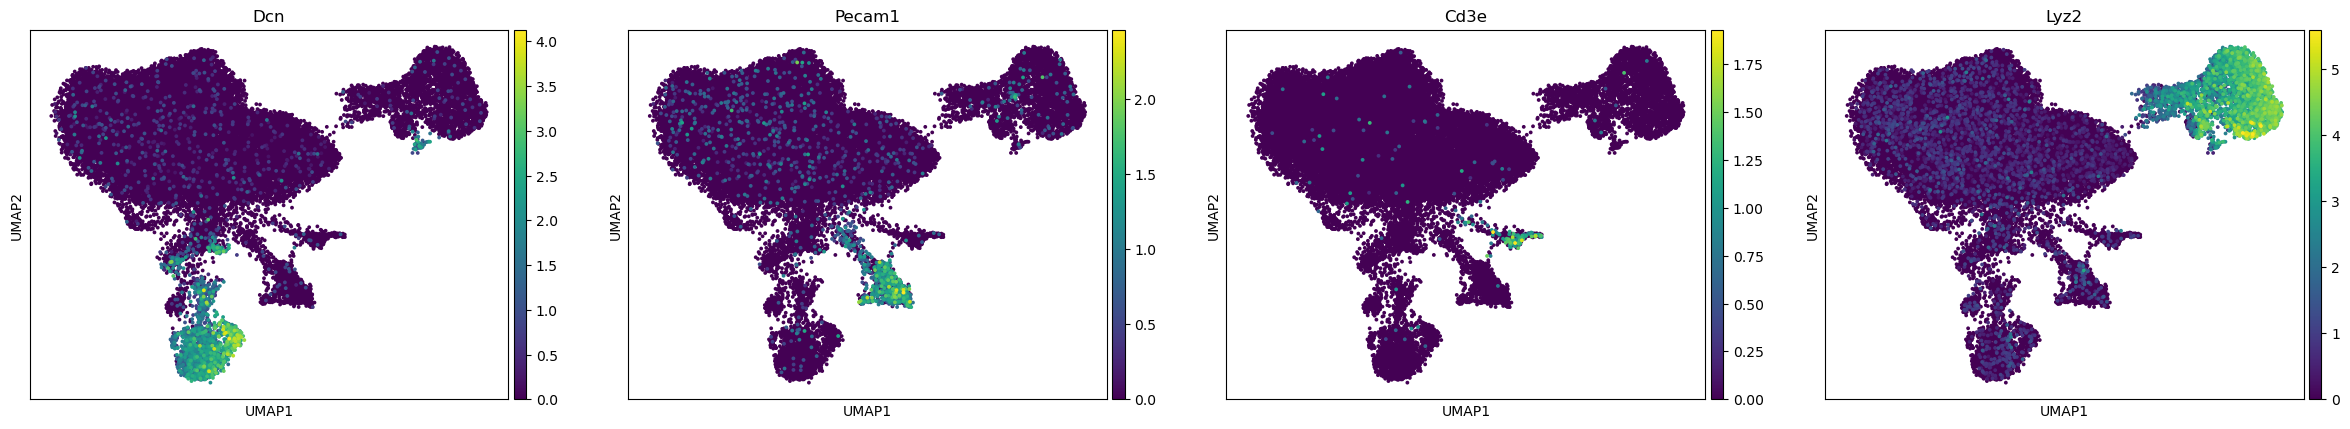

In [10]:
sc.pl.umap(adata, color = ['Dcn', 'Pecam1', 'Cd3e', 'Lyz2'], size = 30)

In [11]:
remove = np.array([7, 10, 13, 11, 14, 6], dtype = str)
adata = adata[~adata.obs.leiden.isin(remove)].copy()
adata

AnnData object with n_obs × n_vars = 29081 × 26602
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

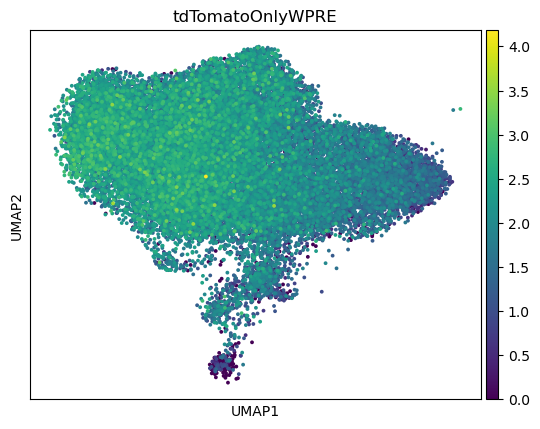

In [12]:
sc.pl.umap(adata, color = 'tdTomatoOnlyWPRE', size = 30)

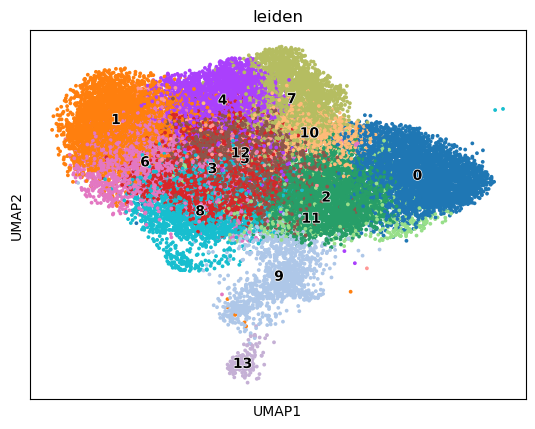

In [13]:
sc.tl.leiden(adata)
sc.pl.umap(adata, color = 'leiden', size = 30, legend_loc = 'on data', legend_fontoutline = True)

In [14]:
adata = adata[adata.obs.leiden != '13'].copy()
adata

AnnData object with n_obs × n_vars = 28902 × 26602
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

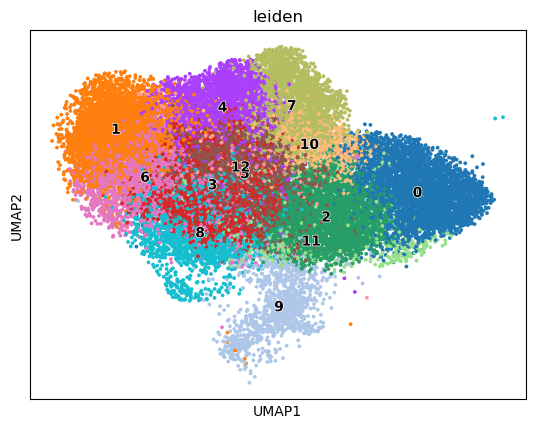

In [15]:
sc.pl.umap(adata, color = 'leiden', size = 30, legend_loc = 'on data', legend_fontoutline = True)

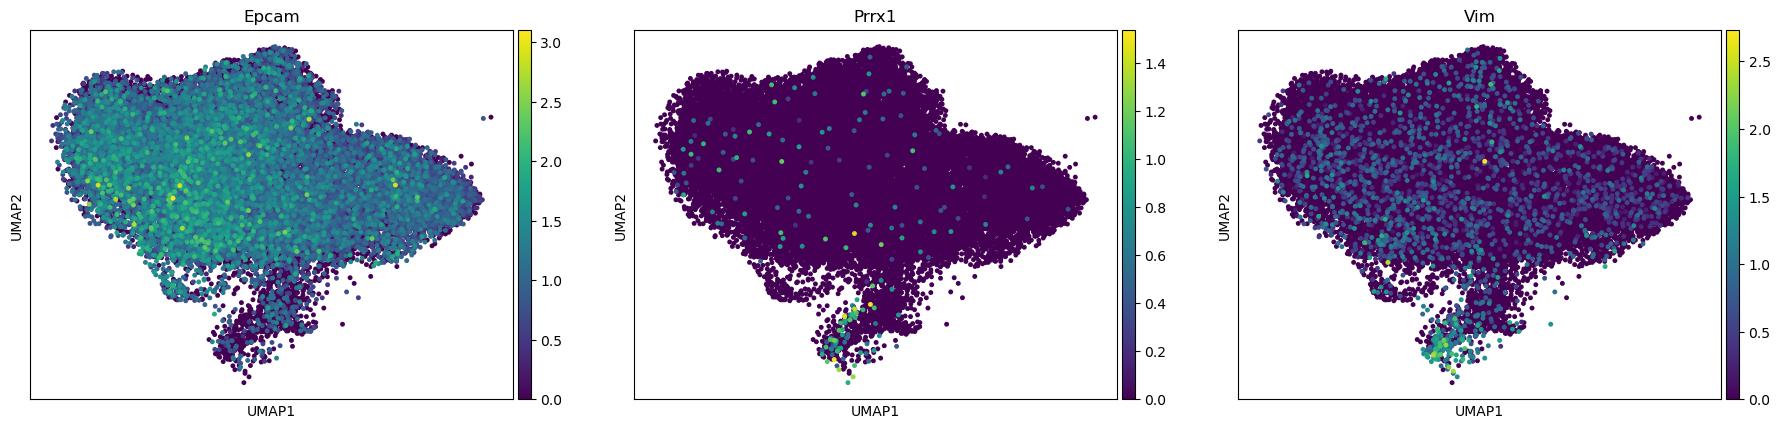

In [16]:
sc.pl.umap(adata, color = ['Epcam', 'Prrx1', 'Vim'], size = 50)

In [17]:
adata = adata[adata.obs.leiden == '9'].copy()
adata

AnnData object with n_obs × n_vars = 1242 × 26602
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

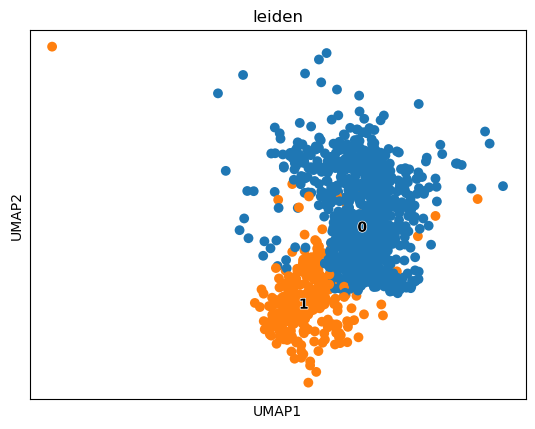

In [22]:
sc.tl.leiden(adata, resolution = .2)
sc.pl.umap(adata, color = 'leiden', size = 200, legend_loc = 'on data', legend_fontoutline = True)

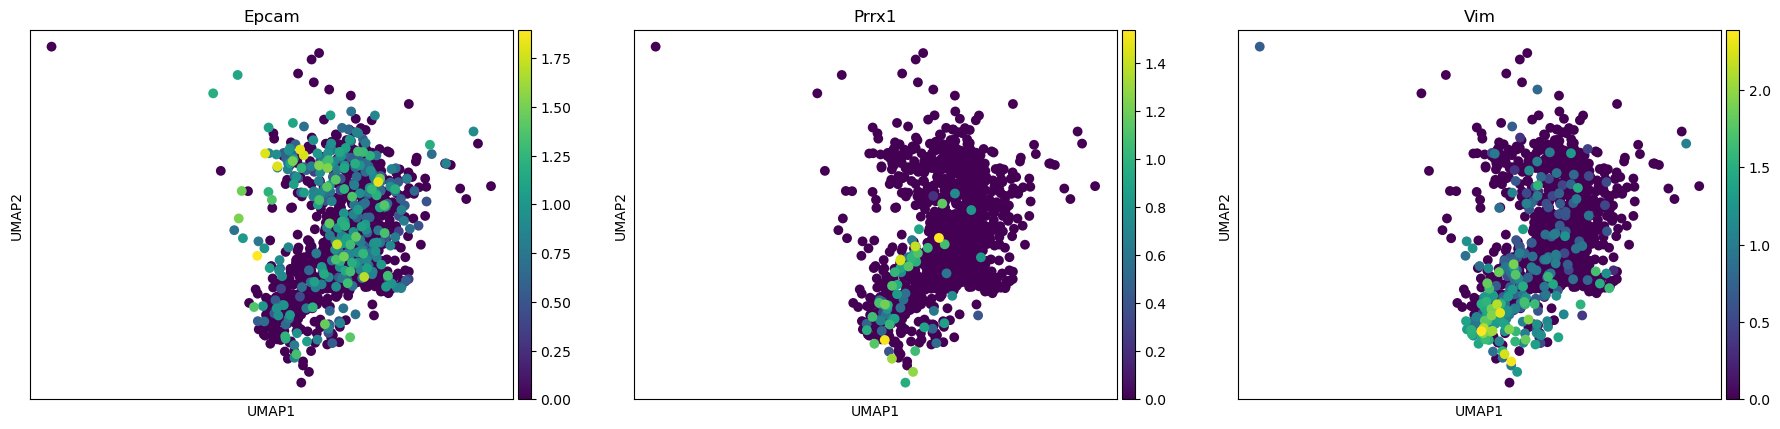

In [23]:
sc.pl.umap(adata, color = ['Epcam', 'Prrx1', 'Vim'], size = 200)

In [24]:
celltype_dict = {
    '0' : 'Epithelial',
    '1' : 'Mesenchymal'}

adata.obs['celltype'] = adata.obs.leiden.map(celltype_dict).astype('category')

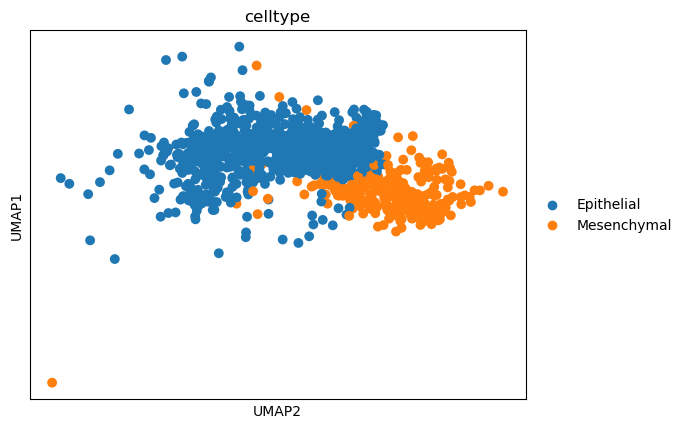

In [27]:
sc.pl.umap(adata, dimensions = [1, 0], color = 'celltype', size = 200, show = False)
plt.gca().invert_xaxis()

In [28]:
adata.write(os.path.join(pth_out, 'MMTV-PyMT.h5ad'))